In [ ]:
# Setup module: load packages
import QuantLib as ql
import pandas as pd
import matplotlib.pyplot as plt
import datetime as dt
import sys
from IPython.display import display
from pathlib import Path

# Load and data
data_directory = Path.cwd().parents[1] / "data"
euribor_file = data_directory / "6M EURIBOR 20260820.xlsx"
ESTR_file    = data_directory / "ESTR 20260820.xlsx"
ESTR_data = pd.read_excel(ESTR_file, 
                          sheet_name="Piecewise Lin. (Simp)",
                          skiprows=8)

# Set the QuantLib evaluationdate
ql.Settings.instance().evaluationDate = ql.Date(20,8,2026)

# Bootstrap the ESTR curve -> code contained in setup file
sys.path.append("..\src")
%run setup4.py

ql.Settings.instance().enforcesTodaysHistoricFixings = False # use the forecast for the fixing if not available
ql.IndexManager.instance().clearHistories()

ESTR curve constructed and ready to use. Setup complete


# Objective
Throughout this module, you'll learn how to model, analyze and price an overnight indexed swap, such as an ESTR-swap. 

# Swap pricing in QuantLib
To model swaps, we need two things:
1. An object representing the swap instrument. This object should contain at least the cash flows and the cash flow dates to be discounted in the pricing process
2. A discount curve from which we can extract the discount factors to discount the cash flows of the swap object. 
For discounting, we use the ESTR curve that we've constructed in a previous module. This curve is loaded in this module by running the initialization in the cell on top. Both the ESTR_index and ESTR_curve are available throughout this module. 

## Create an overnight index swap instrument 
We'll construct a swap instrument using ql.OvernightIndexedSwap(). There are several ways of doing this, see https://quantlib-python-docs.readthedocs.io/en/latest/instruments.html#swaps, but we'll do it by first constructing the payment schedules for the fixed leg, followed by constructing the swap instrument from this schedule. Below is the script to construct a plain vanilla ESTR swap with the following important characteristics:
- issue date: 12 February 2026
- tenor: 10 years
- fixed leg payments: annually
- floating leg payments: annually, extracted from the index
- notional: 10  million EUR
- swap fixed rate: 3%
There are several other parameters passed to the objects, but for now we focus on the most important ones. 

Now let's start by setting the parameters and defining the payment schedules for the fixed and floating legs. 

In [33]:
# parameters
calendar = ql.TARGET()
issueDate = ql.Date(12,2,2026)                                                                      # the issuedate of the swap
unadjustedMaturityDate   = calendar.advance(issueDate, 10, ql.Years, ql.Unadjusted)                 # the unadjusted maturity date according to the calendar TARGET()
fixedLegPaymentFrequency = ql.Period(ql.Annual)                                                     # fixed leg makes annual payments
fixedLegConvention = ql.ModifiedFollowing                                                           # this parameter defines what happens when a cash flow falls on a non-business day: we pick the following business day
dateGeneration = ql.DateGeneration.Backward                                                         # this parameter defines how to generate the coupon dates from the issue- and maturity date. Backward means starting at the unadjusted maturity date and filling the dates backward.
endOfMonth = False


# Fixed leg payment schedule
fixedSchedule = ql.Schedule(
    issueDate,
    unadjustedMaturityDate, # use the unadjusted maturity date
    fixedLegPaymentFrequency,
    ESTR_index.fixingCalendar(),
    fixedLegConvention,
    fixedLegConvention,
    dateGeneration,
    endOfMonth
)


Now we have two ql.Schedule() objects. These objects are basically a series of dates on which our cash flows occur. The objects only contain the dates, not yet the cash flows themselves. Now we can use the schedules alongside some additional parameters to create our plain vanilla swap object. 

In [34]:
# parameters
notional = 10e6
fixedRate = 0.03
fixedLegDayCount = ql.Thirty360(ql.Thirty360.USA)


swap = ql.OvernightIndexedSwap(
    ql.OvernightIndexedSwap.Receiver,
    notional,
    fixedSchedule,
    fixedRate,
    fixedLegDayCount,
    ESTR_index
)

print(swap)

<QuantLib.QuantLib.OvernightIndexedSwap; proxy of <Swig Object of type 'ext::shared_ptr< OvernightIndexedSwap > *' at 0x000001EF296AC270> >


# Swap object in quantlib: fixed leg cash flows

Now we have created our swap object! Let's have a closer look at this. A swap object can be simplified by being a collection of cash flows with corresponding cash flow dates. We can extract this information from the swap object as follows, starting with the fixed rate cash flows.

,Date,Plot date,Fixed leg amount
0,"February 12th, 2027",2027-02-12,300000.000000
1,"February 14th, 2028",2028-02-14,301666.666667
2,"February 12th, 2029",2029-02-12,298333.333333
3,"February 12th, 2030",2030-02-12,300000.000000
4,"February 12th, 2031",2031-02-12,300000.000000
5,"February 12th, 2032",2032-02-12,300000.000000
6,"February 14th, 2033",2033-02-14,301666.666667
7,"February 13th, 2034",2034-02-13,299166.666667
8,"February 12th, 2035",2035-02-12,299166.666667
9,"February 12th, 2036",2036-02-12,300000.000000


Text(0, 0.5, 'Cash flow amount (million EUR)')

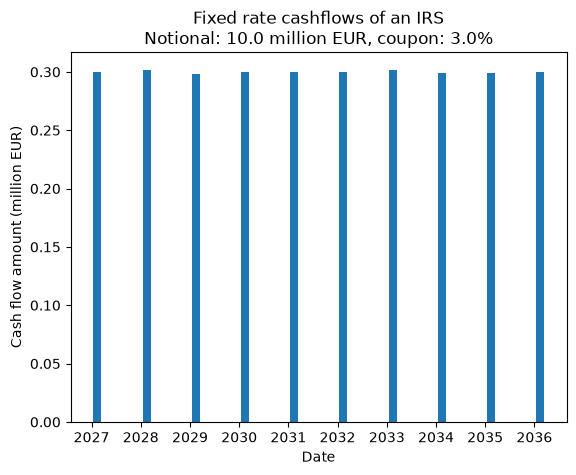

In [35]:
# Extract the fixed cashflows and set it into a table
fixed_cashflows = []

for cf in swap.fixedLeg():
    fixed_cashflows.append({
        'Date': cf.date(),
        'Plot date': dt.date(cf.date().year(), cf.date().month(), cf.date().dayOfMonth()),
        'Fixed leg amount': cf.amount()
    })
fixed_cashflows = pd.DataFrame(fixed_cashflows)

display(fixed_cashflows)

# plot the cashflows
plt.bar(fixed_cashflows['Plot date'], fixed_cashflows['Fixed leg amount']/1e6, width=60)
plt.title(f'Fixed rate cashflows of an IRS\nNotional: {notional/1e6} million EUR, coupon: {fixedRate*100}%')
plt.xlabel('Date')
plt.ylabel('Cash flow amount (million EUR)')

# Swap object in QuantLib: floating leg cash flows
The interest rate on the floating leg cash flow is directly related to the ESTR rate by construction of the swap. Before we look at the cash flows, let's have a closer look on how and when this rate is chosen from the ESTR index. 

A floating leg cash flow is based on the accrued interest over the accrual period before the cash flow date. For annual payments, the accrual period starts one year before the cash flow and ends at the cash flow date.
The corresponding interest rate is set *before* the accrual period starts. For overnight indexed swaps, the interest rate used for the floating leg is the interest rate at the start date of the accrual period. 

For the floating leg cash flows, we distinct the cash flows with rates that are determined in the past and rates that will be determined in the future.

## 1: Floating leg payments with a rate that has been fixed already
For our swap, the first floating interest payment will be one year after issuance, which is February 12th, 2027. The floating rate interest paid over this date is accrued over the first accrual period, starting at issuance (February 12th, 2026) until the first cash flow. As previously described, the rate used for this interest accrual is the ESTR rate at start of the accrual period. In this case, the accrual start is in the past and we already know the ESTR rate at that date. Therefore, the rate is known and we can compute the cashflow. We simply accrue the ESTR fixing of February 12th, 2026 for one year. 

In QuantLib, this can be done automatically by extracting the cash flow from the swap floating leg. The same way as we did for the fixed leg, we can extract the cash flow amount. However, there's some additional work to do before we can do so, because the code below throws an error.

In [36]:
swap.floatingLeg()[0].amount() # the first cash flow of the floating leg

RuntimeError: Missing EoniaON Actual/360 fixing for February 12th, 2026

### Error: missing fixing
Probably, the code above will throw the following error: "RuntimeError: Missing EoniaON Actual/360 fixing for February 12h, 2026". First, think yourself why this error could've been expected. 

$\rightarrow$ Exercise: try to explain how we can determine the floating leg payments? What defines this cash flow? Do we know that value at any given cash flow date in the floating schedule? 


When we want to extract the value of cash flows that have happened in the past (say: before our evaluation date as of 20-08-2026), we need to know the fixings of the ESTR index. Not only do we need to know this ourselves, but also we should store the past fixing values in the index object. The code below loads the fixing data from our database and stores it in the ESTR_index object.

Note that again we're making use of the observer pattern in QuantLib. We store the fixing values in our ESTR_index. We passed this index as parameter to the swap object. Now once we set the index fixings, our swap can read these fixings from the index and by doing that, knowing the floating leg payments.

In [37]:
# Load ESTR fixing data from data folder
data_directory = Path.cwd().parents[1] / "data"
ESTR_fixings_file = data_directory / "ESTRON Index 20260212-20260820.xlsx"

ESTR_fixings = pd.read_excel(ESTR_fixings_file)

# add the quantlib date as column to the data
ESTR_fixings['AsOfDate'] = ESTR_fixings.apply(
    lambda row: ql.Date(
        int(row['Day']),
        int(row['Month']),
        int(row['Year'])
    ),
    axis=1
)
# display(ESTR_fixings)

# clean the index from other stored fixings such that it's clean and ready to use
ql.IndexManager.instance().clearHistories()

# add all fixings to the index
for idx, row in ESTR_fixings.iterrows():
    if pd.notna(row['ESTRON Index']):
        ESTR_index.addFixing(row['AsOfDate'], row['ESTRON Index']/100)

And now we're able to extract the first cash flow from our swap object:

In [38]:
print(swap.floatingLeg()[0].amount()) # the first cash flow of the floating leg
print(swap.floatingLeg()[0].date())

228763.11448548402
February 12th, 2027


## 2: Floating leg payments with a rate that will be fixed in the future
The second floating leg interest payment will be on February 14th, 2028. The accrual period starts at February 12th, 2027 and the rate used for the interest is the 1-year ESTR rate [Note to self: check if the one-year rate is used or that they use accrual of O/N ESTR rates]. Note that we cannot extract the rate from the ESTR index, as February 12th, 2027 lies in the future (today is August 20th, 2026). 

The future ESTR rate for the floating leg payment is derived from our forward curve. Remind the module on term structures, where we discussed the forward curves. The market implied forward rates are used to compute the *expected* floating leg cash flow. We say *expected* because the rate that we see today can be different tomorrow. Forward rates are related to market rates and change constantly. Therefore, the floating leg cash flows that we see today won't be the same as the one we see when we analyze the same swap tomorrow. 

In QuantLib, the swap was linked to the ESTR index by construction. Also, the ESTR index is linked to the ESTR curve. QuantLib directly links the floating leg swap payments to this ESTR curve and allows you to compute the expected floating leg payment directly from the swap object:

In [39]:
print(swap.floatingLeg()[1].date()) # the second floating leg cash flow
print(swap.floatingLeg()[1].amount())

February 14th, 2028
286316.82164745656


## Extract floating cash flows
Now have a look at all cash flows of the swap together

,Date,Plot date,Fixed leg amount
0,"February 12th, 2027",2027-02-12,228763.114485
1,"February 14th, 2028",2028-02-14,286316.821647
2,"February 12th, 2029",2029-02-12,284406.481137
3,"February 12th, 2030",2030-02-12,288731.736644
4,"February 12th, 2031",2031-02-12,295574.873120
5,"February 12th, 2032",2032-02-12,304001.596989
6,"February 14th, 2033",2033-02-14,317758.551436
7,"February 13th, 2034",2034-02-13,326766.079256
8,"February 12th, 2035",2035-02-12,338127.797860
9,"February 12th, 2036",2036-02-12,348350.628258


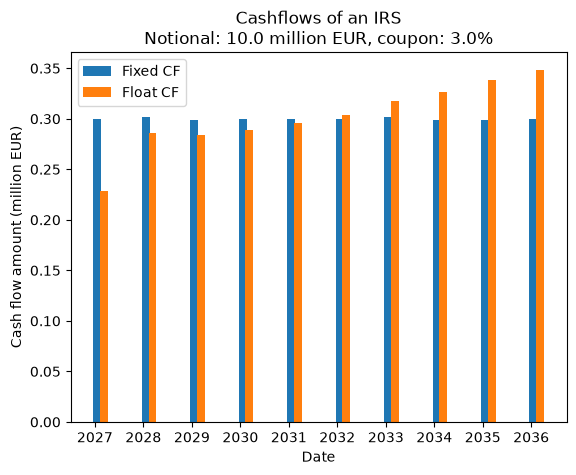

In [40]:
# Extract the fixed cashflows and set it into a table
floating_cashflows = []

for cf in swap.floatingLeg():
    floating_cashflows.append({
        'Date': cf.date(),
        'Plot date': dt.date(cf.date().year(), cf.date().month(), cf.date().dayOfMonth()),
        'Fixed leg amount': cf.amount()
    })

floating_cashflows = pd.DataFrame(floating_cashflows)
display(floating_cashflows)

# plot the cashflows
offset = pd.Timedelta(days=25) # to avoid plotting the bars on top of eachother
plt.bar(fixed_cashflows['Plot date'] - offset, fixed_cashflows['Fixed leg amount']/1e6, width=60, label = 'Fixed CF')
plt.bar(fixed_cashflows['Plot date'] + offset, floating_cashflows['Fixed leg amount']/1e6, width=60, label = 'Float CF')
plt.title(f'Cashflows of an IRS\nNotional: {notional/1e6} million EUR, coupon: {fixedRate*100}%')
plt.xlabel('Date')
plt.ylabel('Cash flow amount (million EUR)')
plt.legend()

Now you see that the object is able to extract the floating leg cash flows as well. The plot also shows the difference in the fixed and floating payments. It's visible that the expected floating interest payments are lower in the first half of the swaps life, and higher in the second half. This pattern can be explained by the 1-year forward curve, as we will do below.

## Link the floating leg cash flows to the one-year ESTR forward rate
We can compute an expected floating leg cash flow using the forward rate as follows
$$\text{Expected cash flow} = \text{notional} * ((1 + \text{forward rate})^{\text{time period}}-1),$$
Where the notional is the swap notional, the forward rate is the ESTR forward rate over the accrual period, and the time period is the time of the accrual period in years.

The code below is an example that applying this formula on the second last cash flow of our swap provides the same result as extracting the cash flow from the swap object directly. This shows how the forward curve is used to compute expected floating leg cash flows for a swap automatically with QuantLib.

In [75]:
# extract the second last coupon from the swap object
coupon = ql.as_overnight_indexed_coupon(swap.floatingLeg()[-2])
accrualStartDate = coupon.accrualStartDate()
accrualEndDate   = coupon.date()
accrualPeriod    = coupon.accrualPeriod()
print(f'The second last coupon starts accruing interest on {accrualStartDate}, occurs on {accrualEndDate}.\nThe accrual period is {round(accrualPeriod,4)} years.')

# extract the corresponding foward rate from the ESTR curve. Use same compounding as the coupon
forward_rate     = ESTR_curve.forwardRate(
    accrualStartDate, 
    accrualEndDate, 
    coupon.dayCounter(),
    ql.Compounded,
    ql.Annual
).rate()
print(f'\nThe 1-year forward ESTR rate over the accrual period is {round(forward_rate * 100, 2)}%')

# The expected cash flow based on the forward rate is
expected_cf = notional * ((1 + forward_rate) ** accrualPeriod - 1)
print(f'\nThe cash flow we expect based on the obtained forward rate and the accrual period is {expected_cf}')

# Compare to the actual cash flow
actual_cf   = coupon.amount()
print(f'\nThe actual cash flow in the swap object is {actual_cf}')

The second last coupon starts accruing interest on February 13th, 2034, occurs on February 12th, 2035.
The accrual period is 1.0111 years.

The 1-year forward ESTR rate over the accrual period is 3.34%

The cash flow we expect based on the obtained forward rate and the accrual period is 338127.797860206

The actual cash flow in the swap object is 338127.797860206


## Swap pricing: computing the net present value (NPV)
So far, we've had a close look at our swap object, understanding both the fixed and floating leg payments. Now it's time to price the swap! By pricing, we mean computing its net present value (NPV). Conceptually, this works exactly the same as pricing the bond as in the previous module. 

Computing the NPV of the swap is nothing more than computing the NPV of each cash flow of the swap. In this module, we've seen how to extract all those cash flows from the swap object. Although it's possible to discount each cash flow separately, we've already seen for the bond that QuantLib has a few build in functions to do this automatically. We'll directly apply the build in QuantLib functionality, but feel free to practice with discounting the cash flows yourself!

Remember that for discounting cash flows, we needed to take four steps:
1. Create an empty yield term structure handle that will point towards the discount curve
2. Create a discount engine. This is a bundle of functionalities that takes a curve and an instrument and knows how to price it. In our case, this is where the discounting cash flow magic happens. Ensure that the engine takes the discounting curve handle as parameter such that it understands where to get the discount factors from.
3. Couple the pricing enginge to our swap object, such that the object knows what 'pricing' means
4. Link the discount curve to a discount curve of choice. In our case, use the ESTR curve that we've created before.

In [76]:
# Create a handle to your discounting curve
discounting_curve_handle = ql.RelinkableYieldTermStructureHandle()              # empty handle, doesn't point to any curve yet

# Create a discounting bond engine
discounting_swap_engine = ql.DiscountingSwapEngine(discounting_curve_handle)    # pricing engine linked to a curve handle

# Connect the engine to your bond
swap.setPricingEngine(discounting_swap_engine)                                  # set the pricing engine of your bond

# Select a curve as discount curve and link your handle
discounting_curve_handle.linkTo(ESTR_curve)                                     # link your discount handle to the ESTR curve such that you use the ESTR curve for discounting

And now it's time to compute the net present value of your first swap!

In [77]:
swap.NPV()

6770.283724786714

# Challenge
By now you've seen all important parts that come into play pricing an ESTR swap with annual coupon payments. To deepen your knowledge, have a thought on what would happen if tomorrow the ESTR curve moves up by one basis point in parallel. This module won't imply this situation, but it is very helpful to give it a first thought. Try to explain what happens to the following items, given that all ESTR market quotes will move up by one basis point:
- What will happen to the zero rates, discount factors, and forward rates? 
- What will happen to the fixed leg cash flows? 
- What will happen to the floating leg cash flows? Relate it to the formula!
- What will happen to the discount factors used to compute the NPV of all cash flows? 
- What will happen to the NPV of the swap?